<a href="https://colab.research.google.com/github/adukirdat/deep_learning/blob/main/Adam_Optimizer_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)
print("Libraries imported successfully!")

NumPy Version: 2.4.6
Libraries imported successfully!


In [2]:
# Input data (features)
X = np.array([
    [1, 0, 1, 0],
    [1, 0, 1, 1],
    [0, 1, 0, 1]
])

# Transpose input data
X = X.T

print("Input X:\n", X)
print("Shape of X:", X.shape)

# Output labels
y = np.array([[1], [1], [0]])

# Transpose output data
y = y.T

print("\nActual Output y:\n", y)
print("Shape of y:", y.shape)

Input X:
 [[1 1 0]
 [0 0 1]
 [1 1 0]
 [0 1 1]]
Shape of X: (4, 3)

Actual Output y:
 [[1 1 0]]
Shape of y: (1, 3)


In [3]:
# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Testing sigmoid function
print("Sigmoid(0):", sigmoid(0))
print("Sigmoid(2):", sigmoid(2))
print("Sigmoid(-2):", sigmoid(-2))

Sigmoid(0): 0.5
Sigmoid(2): 0.8807970779778823
Sigmoid(-2): 0.11920292202211755


In [4]:
lr = 0.01
epochs = 10000

inputlayer_neurons = X.shape[0]
hiddenlayer_neurons = 3
output_neurons = 1

print("Learning Rate:", lr)
print("Epochs:", epochs)
print("Input Neurons:", inputlayer_neurons)
print("Hidden Neurons:", hiddenlayer_neurons)
print("Output Neurons:", output_neurons)

Learning Rate: 0.01
Epochs: 10000
Input Neurons: 4
Hidden Neurons: 3
Output Neurons: 1


In [5]:
# Initialize weights between input and hidden layer
w_ih = np.random.uniform(size=(inputlayer_neurons, hiddenlayer_neurons))

# Initialize weights between hidden and output layer
w_ho = np.random.uniform(size=(hiddenlayer_neurons, output_neurons))

print("Input to Hidden Weights:\n", w_ih)
print("\nHidden to Output Weights:\n", w_ho)

print("\nShape of w_ih:", w_ih.shape)
print("Shape of w_ho:", w_ho.shape)

Input to Hidden Weights:
 [[0.59223575 0.90594062 0.56616159]
 [0.51503336 0.76046261 0.46848663]
 [0.31791204 0.10815187 0.32299821]
 [0.70130724 0.7262973  0.18001986]]

Hidden to Output Weights:
 [[0.85840769]
 [0.94098819]
 [0.64197601]]

Shape of w_ih: (4, 3)
Shape of w_ho: (3, 1)


In [6]:
# Momentum parameter
beta = 0.9

# Initialize velocity for both weight matrices
v_w_ih = np.zeros_like(w_ih)
v_w_ho = np.zeros_like(w_ho)

print("Beta:", beta)
print("\nVelocity for Input-Hidden Weights:\n", v_w_ih)
print("\nVelocity for Hidden-Output Weights:\n", v_w_ho)

Beta: 0.9

Velocity for Input-Hidden Weights:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

Velocity for Hidden-Output Weights:
 [[0.]
 [0.]
 [0.]]


In [7]:
# Forward propagation
hidden_layer_input = np.dot(w_ih.T, X)
hidden_layer_output = sigmoid(hidden_layer_input)

output_layer_input = np.dot(w_ho.T, hidden_layer_output)
predicted_output = sigmoid(output_layer_input)

print("Hidden Layer Output:\n", hidden_layer_output)
print("\nPredicted Output:\n", predicted_output)

Hidden Layer Output:
 [[0.7130304  0.8336133  0.77141892]
 [0.73382029 0.85073657 0.81559146]
 [0.70871675 0.74444088 0.65667382]]

Predicted Output:
 [[0.85290458 0.88016845 0.8642706 ]]


In [8]:
# Calculate Mean Squared Error
error = y - predicted_output
loss = np.mean(error ** 2)

print("Actual Output:\n", y)
print("\nPrediction:\n", predicted_output)
print("\nError:\n", error)
print("\nMean Squared Error:", loss)

Actual Output:
 [[1 1 0]]

Prediction:
 [[0.85290458 0.88016845 0.8642706 ]]

Error:
 [[ 0.14709542  0.11983155 -0.8642706 ]]

Mean Squared Error: 0.26098677707409684


In [9]:
# Calculate output layer error
output_error = y - predicted_output

# Calculate output layer delta
output_delta = output_error * predicted_output * (1 - predicted_output)

# Calculate hidden layer error
hidden_error = np.dot(w_ho, output_delta)

# Calculate hidden layer delta
hidden_delta = hidden_layer_output * (1 - hidden_layer_output) * hidden_error

print("Output Delta:\n", output_delta)
print("\nHidden Delta:\n", hidden_delta)

Output Delta:
 [[ 0.01845435  0.01263887 -0.10138493]]

Hidden Delta:
 [[ 0.00324143  0.00150482 -0.01534608]
 [ 0.00339194  0.00151022 -0.01434866]
 [ 0.00244571  0.00154365 -0.01467401]]


In [10]:
# Calculate gradients for both weight matrices
d_w_ho = np.dot(hidden_layer_output, output_delta.T)
d_w_ih = np.dot(X, hidden_delta.T)

print("Gradient of Hidden-Output Weights:\n", d_w_ho)
print("\nGradient of Input-Hidden Weights:\n", d_w_ih)

print("\nShape of d_w_ho:", d_w_ho.shape)
print("Shape of d_w_ih:", d_w_ih.shape)

Gradient of Hidden-Output Weights:
 [[-0.05451581]
 [-0.05839416]
 [-0.04408903]]

Gradient of Input-Hidden Weights:
 [[ 0.00474625  0.00490216  0.00398936]
 [-0.01534608 -0.01434866 -0.01467401]
 [ 0.00474625  0.00490216  0.00398936]
 [-0.01384126 -0.01283844 -0.01313036]]

Shape of d_w_ho: (3, 1)
Shape of d_w_ih: (4, 3)


In [11]:
# Update velocity using momentum
v_w_ho = beta * v_w_ho + (1 - beta) * d_w_ho
v_w_ih = beta * v_w_ih + (1 - beta) * d_w_ih

# Update weights
w_ho = w_ho + lr * v_w_ho
w_ih = w_ih + lr * v_w_ih

print("Updated Input-Hidden Weights:\n", w_ih)
print("\nUpdated Hidden-Output Weights:\n", w_ho)

Updated Input-Hidden Weights:
 [[0.5922405  0.90594552 0.56616558]
 [0.51501802 0.76044826 0.46847195]
 [0.31791678 0.10815677 0.3230022 ]
 [0.7012934  0.72628447 0.18000673]]

Updated Hidden-Output Weights:
 [[0.85835318]
 [0.9409298 ]
 [0.64193192]]


In [12]:
# Forward propagation with updated weights
hidden_layer_input = np.dot(w_ih.T, X)
hidden_layer_output = sigmoid(hidden_layer_input)

output_layer_input = np.dot(w_ho.T, hidden_layer_output)
predicted_output = sigmoid(output_layer_input)

# Calculate new loss
error = y - predicted_output
new_loss = np.mean(error ** 2)

print("Updated Prediction:\n", predicted_output)
print("\nNew Loss:", new_loss)

Updated Prediction:
 [[0.85289097 0.8801548  0.86425524]]

New Loss: 0.2609803528992973


### Adam Optimizer Implementation
Now we will implement the **Adam Optimizer** which combines **Momentum** (first moment) and **RMSProp** (second moment), along with bias correction to stabilize early iterations.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Re-initialize weights for a clean Adam training run
w_ih = np.random.uniform(size=(inputlayer_neurons, hiddenlayer_neurons))
w_ho = np.random.uniform(size=(hiddenlayer_neurons, output_neurons))

# Initialize Adam moment estimates
m_ih = np.zeros_like(w_ih)
v_ih = np.zeros_like(w_ih)
m_ho = np.zeros_like(w_ho)
v_ho = np.zeros_like(w_ho)

# Hyperparameters
beta1 = 0.9      # Momentum decay rate
beta2 = 0.999    # RMSProp decay rate
epsilon = 1e-8
lr = 0.01
epochs = 10000

error_adam = []

for epoch in range(1, epochs + 1):
    # 1. Forward Propagation
    hidden_layer_input = np.dot(w_ih.T, X)
    hidden_layer_output = sigmoid(hidden_layer_input)

    output_layer_input = np.dot(w_ho.T, hidden_layer_output)
    predicted_output = sigmoid(output_layer_input)

    # 2. Compute Loss (MSE)
    loss = np.mean((y - predicted_output) ** 2)
    error_adam.append(loss)

    # 3. Backpropagation (Gradients computation)
    output_error = y - predicted_output
    output_delta = output_error * predicted_output * (1 - predicted_output)

    hidden_error = np.dot(w_ho, output_delta)
    hidden_delta = hidden_layer_output * (1 - hidden_layer_output) * hidden_error

    d_w_ho = np.dot(hidden_layer_output, output_delta.T)
    d_w_ih = np.dot(X, hidden_delta.T)

    # we minimize loss: gradient of loss is negative of these updates
    grad_w_ho = -d_w_ho
    grad_w_ih = -d_w_ih

    # 4. Adam Updates
    # Update first moment (Momentum)
    m_ho = beta1 * m_ho + (1 - beta1) * grad_w_ho
    m_ih = beta1 * m_ih + (1 - beta1) * grad_w_ih

    # Update second moment (RMSProp)
    v_ho = beta2 * v_ho + (1 - beta2) * (grad_w_ho ** 2)
    v_ih = beta2 * v_ih + (1 - beta2) * (grad_w_ih ** 2)

    # Bias correction
    m_ho_hat = m_ho / (1 - beta1 ** epoch)
    m_ih_hat = m_ih / (1 - beta1 ** epoch)
    v_ho_hat = v_ho / (1 - beta2 ** epoch)
    v_ih_hat = v_ih / (1 - beta2 ** epoch)

    # Update weights
    w_ho -= lr * m_ho_hat / (np.sqrt(v_ho_hat) + epsilon)
    w_ih -= lr * m_ih_hat / (np.sqrt(v_ih_hat) + epsilon)

print("Final Loss:", error_adam[-1])


Final Loss: 1.4678745655388012e-06


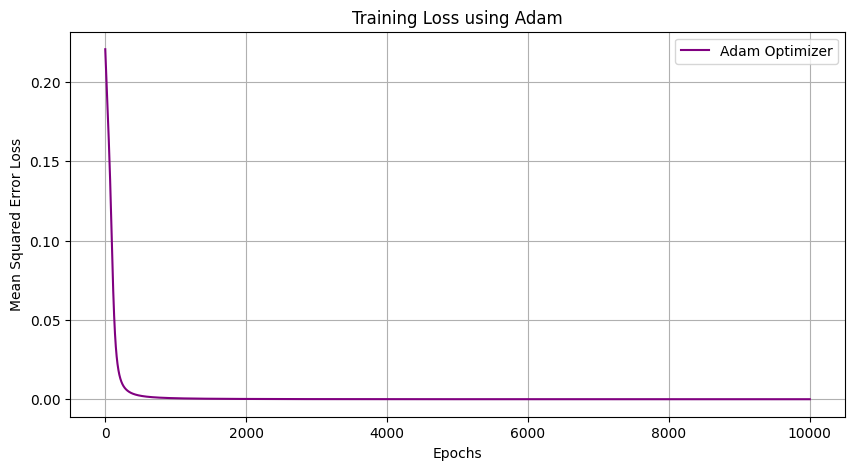

In [14]:
# Plot the loss curve
plt.figure(figsize=(10, 5))
plt.plot(error_adam, label="Adam Optimizer", color="purple")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error Loss")
plt.title("Training Loss using Adam")
plt.grid(True)
plt.legend()
plt.show()